# Lab07 · Aprendizaje no supervisado con K-Means
**Universitario**    Espinoza Chiri Soledad Griselda
**Carrera** Ing. De Sistemas

** Punto 1. **
Modificar el generador de dataset aleatorio, para que este pueda generar centroides en cantidades entre 1 y 20, y considerando una importante distancia entre ellos con la finalidad de permitir la verificación visual una vez se realice el entrenamiento del modelo.
Establecer aleatoriamente las posiciones de los centroides.
Establecer aleatoriamente las distancias de los puntos generados con respecto a los centroides.
Establecer aleatoriamente el numero de puntos por centroide.
Aplicar KMeans y visualizar la ubicacion final de los centroides, el numero de puntos por cada centroide y los 5 puntos mas cercanos a cada centroide.
Graficar todo el proceso.

** Punto 2. ** Realizar todo lo anterior pero para puntos 3D.

 ** punto 3  ** Buscar un dataset de imágenes o audio que no tenga etiquetas, que tenga un n mayor a 10 y un m mayor a 10.000 ejemplos, en cualquier ámbito.

Aplicar aprendizaje semisupervisado
Aplicar aprendizaje activo


## 1. Generación aleatoria de los centros originales

Se sortean entre 1 y 20 centros en el plano y se acepta un nuevo centro solo si está al menos a `distancia_minima` de todos los anteriores. `semilla` permite reproducir el experimento.

In [ ]:
import numpy as np

semilla = np.random.default_rng(10)


n_centros = semilla.integers(1, 21)

distancia_minima = 15

blob_centers = []

while len(blob_centers) < n_centros:


    nuevo = semilla.uniform(-100, 100, size=2)


    if all(
        np.linalg.norm(nuevo - centro) >= distancia_minima
        for centro in blob_centers
    ):
        blob_centers.append(nuevo)

blob_centers = np.array(blob_centers)

print("Cantidad de centroides:", n_centros)
print(blob_centers)

Cantidad de centroides: 16
[[-58.46363798  65.68897705]
 [-70.14357538   2.56092329]
 [-72.8160792   37.80729596]
 [ 68.34954486 -14.89820052]
 [ 91.38520069  65.06658128]
 [-32.35693751  15.15210959]
 [ 50.66037294  65.4207874 ]
 [ 86.68769417 -71.00106101]
 [ 49.11604221 -72.12972123]
 [ 81.30575122 -54.77711327]
 [ 70.64794998 -38.73642689]
 [ 93.96607364   3.56684272]
 [-35.50508825 -43.51329657]
 [ 21.17299916 -33.24710866]
 [-70.11701988 -72.6421701 ]
 [-50.21581248 -23.43506669]]


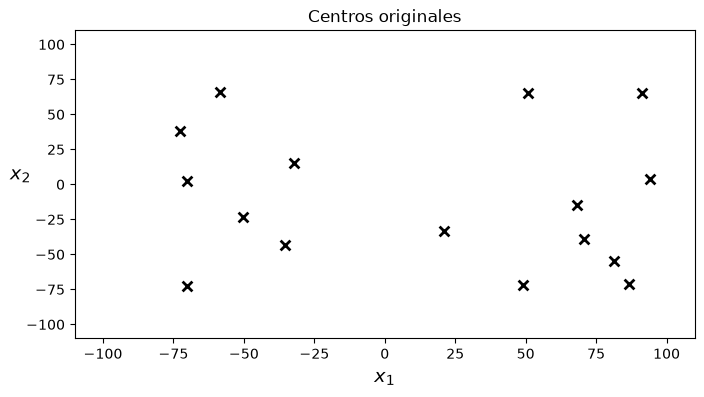

In [ ]:
import matplotlib.pyplot as plt

# Funciones de visualización del cuadernillo del ingeniero.
def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)

def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=10, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=10,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                 cmap="Pastel2")
    if clusterer.n_clusters > 1:
        plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                    linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)
    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

plt.figure(figsize=(8, 4))
plot_centroids(blob_centers)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.xlim(-110, 110)
plt.ylim(-110, 110)
plt.title("Centros originales")
plt.show()

## 2. Generación de los puntos

`cluster_std` controla la dispersión de cada grupo; `n_samples` recibe una cantidad de puntos por centro original. Aquí ambos valores se sortean independientemente para cada grupo.

In [ ]:
from sklearn.datasets import make_blobs

blob_std = semilla.uniform(8.0, 18.0, size=n_centros)

n_puntos_por_centroide = semilla.integers(100, 1001, size=n_centros)


X, y = make_blobs(
    n_samples=n_puntos_por_centroide,
    centers=blob_centers,
    cluster_std=blob_std,
    random_state=10
)


print("Cantidad de centroides:", n_centros)
print("Desviaciones estándar:", blob_std)
print("Puntos por centroide:", n_puntos_por_centroide)

print("\nTotal de puntos:", sum(n_puntos_por_centroide))
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Cantidad de centroides: 16
Desviaciones estándar: [14.49079057 16.3756376  15.76031947 11.39515575  9.48568738 12.57019387
 12.37864358 13.7421759  11.73269224 14.33825057  9.14644359 10.33090474
 15.67241017 17.87124272 16.08001079 16.42965644]
Puntos por centroide: [961 604 816 319 511 815 765 479 621 431 506 132 344 769 879 825]

Total de puntos: 9777
Dimensiones de X: (9777, 2)
Dimensiones de y: (9777,)


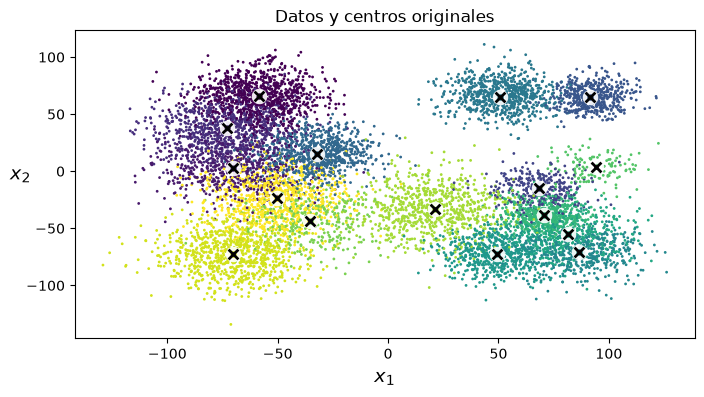

In [ ]:
plt.figure(figsize=(8, 4))
plot_clusters(X, y)
plot_centroids(blob_centers)
plt.title("Datos y centros originales")
plt.show()

## 3. Entrenamiento: Lloyd frente a Elkan

Los dos algoritmos optimizan el mismo objetivo de K-Means; Elkan puede reducir cálculos de distancia a costa de trabajo y memoria adicionales. El tiempo de una sola ejecución **no demuestra** cuál es siempre más rápido. Ambos modelos usan exactamente los mismos parámetros (salvo `algorithm`) y la misma semilla.

In [ ]:
import time
from sklearn.cluster import KMeans

t0 = time.perf_counter()
kmeans_lloyd = KMeans(
    n_clusters=n_centros,
    init="k-means++",
    n_init=10,
    max_iter=300,
    algorithm="lloyd",
    random_state=10
)
kmeans_lloyd.fit(X)
t_lloyd = time.perf_counter() - t0

t0 = time.perf_counter()
kmeans_elkan = KMeans(
    n_clusters=n_centros,
    init="k-means++",
    n_init=10,
    max_iter=300,
    algorithm="elkan",
    random_state=10
)
kmeans_elkan.fit(X)
t_elkan = time.perf_counter() - t0

print("Lloyd")
print("Inercia:", kmeans_lloyd.inertia_)
print("Iteraciones:", kmeans_lloyd.n_iter_)
print("Tiempo:", t_lloyd)

print("\nElkan")
print("Inercia:", kmeans_elkan.inertia_)
print("Iteraciones:", kmeans_elkan.n_iter_)
print("Tiempo:", t_elkan)

Lloyd
Inercia: 2692938.4406948043
Iteraciones: 32
Tiempo: 2.5695067000001472

Elkan
Inercia: 2692938.4406948043
Iteraciones: 32
Tiempo: 0.2895635999998376


### Comparación visual entre ambos modelos

Se utiliza `plot_decision_boundaries` del cuadernillo del ingeniero: regiones de color pastel, puntos negros y centroides marcados con una cruz. Los identificadores de los grupos son arbitrarios. Para calcular la coincidencia entre Lloyd y Elkan se emparejan sus centroides por distancia.

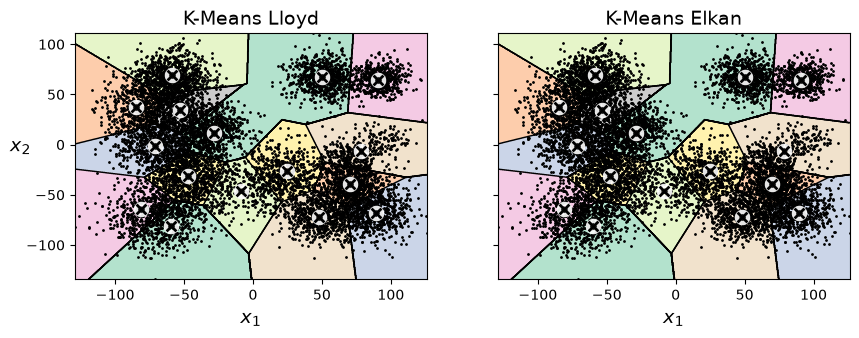

Coincidencia Lloyd vs. Elkan: 100.00%
Diferencia de inercia: 0.00000000


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

# 1) Elkan -> Lloyd: emparejar por cercanía entre centroides aprendidos.
distancias_entre_modelos = cdist(
    kmeans_lloyd.cluster_centers_, kmeans_elkan.cluster_centers_
)
filas, columnas = linear_sum_assignment(distancias_entre_modelos)
equivalencias = np.empty(kmeans_elkan.n_clusters, dtype=int)
equivalencias[columnas] = filas

plt.figure(figsize=(10, 3.2))
plt.subplot(121)
plot_decision_boundaries(kmeans_lloyd, X)
plt.title("K-Means Lloyd", fontsize=14)

plt.subplot(122)
plot_decision_boundaries(kmeans_elkan, X, show_ylabels=False)
plt.title("K-Means Elkan", fontsize=14)
plt.show()

etiquetas_elkan_alineadas = equivalencias[kmeans_elkan.labels_]
coincidencia = np.mean(kmeans_lloyd.labels_ == etiquetas_elkan_alineadas)
print(f"Coincidencia Lloyd vs. Elkan: {coincidencia:.2%}")
print(f"Diferencia de inercia: {abs(kmeans_lloyd.inertia_ - kmeans_elkan.inertia_):.8f}")

## 4. Lloyd elegido: centros finales y vecinos más próximos

Se muestran los puntos y centroides con las funciones del cuadernillo. Los círculos rojos señalan los cinco puntos asignados más cercanos a cada centroide. Debajo se imprimen las coordenadas y el número de puntos por grupo.

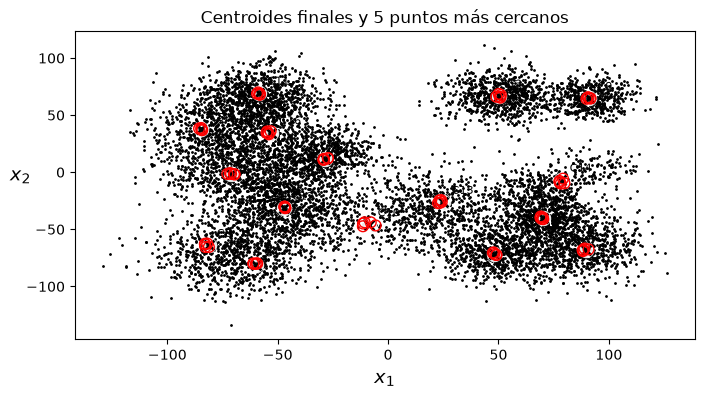

Puntos asignados en total: 9,777 / 9,777


In [ ]:
labels = kmeans_lloyd.labels_
centroides = kmeans_lloyd.cluster_centers_
k = kmeans_lloyd.n_clusters
resumen_clusters = []

plt.figure(figsize=(8, 4))
plot_data(X)

for i in range(k):
    puntos_cluster = X[labels == i]
    centroide = centroides[i]
    n_puntos = len(puntos_cluster)
    distancias = np.linalg.norm(puntos_cluster - centroide, axis=1)
    indices_cercanos = np.argsort(distancias)[:min(5, n_puntos)]
    puntos_cercanos = puntos_cluster[indices_cercanos]
    distancias_cercanas = distancias[indices_cercanos]

    plt.scatter(puntos_cercanos[:, 0], puntos_cercanos[:, 1],
                facecolors='none', edgecolors='r', s=60, zorder=12)
    plt.annotate(f"C{i+1}", centroide, xytext=(6, 6),
                 textcoords='offset points', fontsize=8, zorder=13)
    resumen_clusters.append({
        'cluster': i + 1,
        'centroide': centroide,
        'n_puntos': n_puntos,
        'puntos_cercanos': puntos_cercanos,
        'distancias_cercanas': distancias_cercanas
    })

plot_centroids(centroides)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.title("Centroides finales y 5 puntos más cercanos")
plt.show()

print(f"Puntos asignados en total: {sum(c['n_puntos'] for c in resumen_clusters):,} / {len(X):,}")

### Acercamiento: los 5 puntos más próximos de cada centroide

En la vista general los vecinos cercanos pueden quedar ocultos por la escala. Esta cuadrícula muestra cada centroide **con zoom**, sus cinco puntos vecinos resaltados y algunos puntos del entorno, sin alterar el modelo.

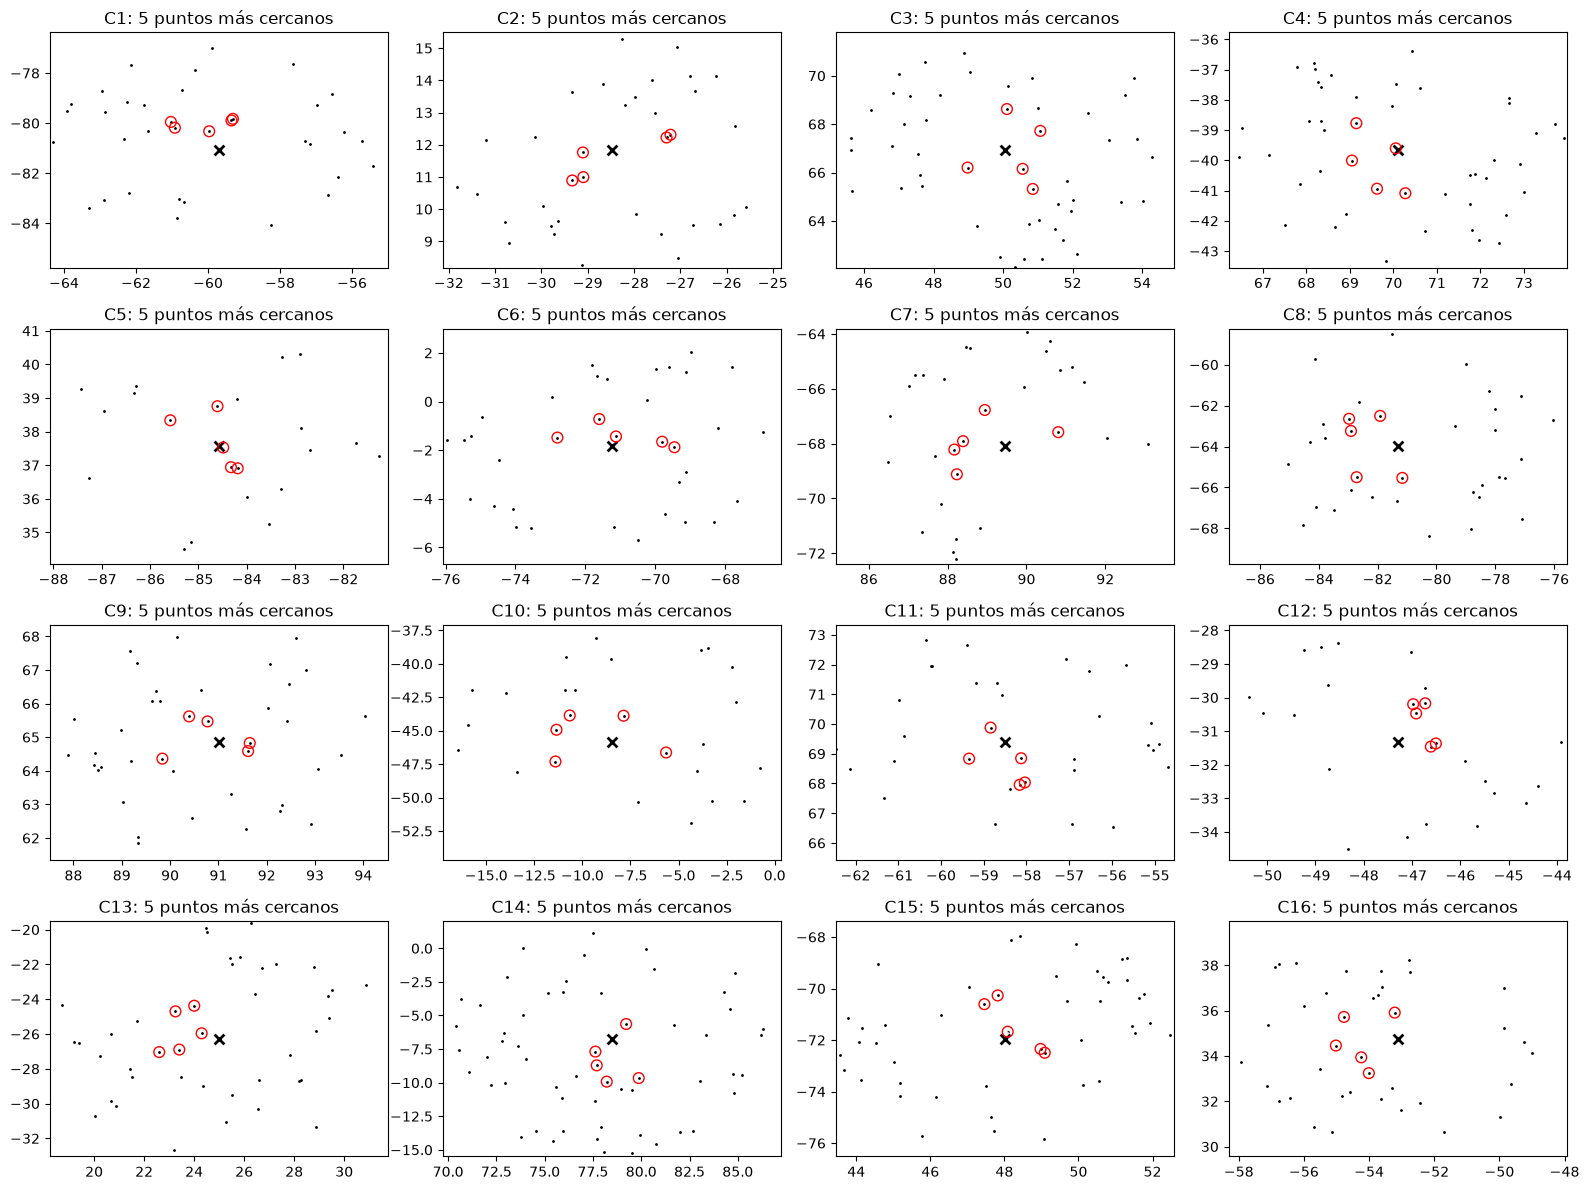

In [ ]:
import math

n_columnas = min(4, k)
n_filas = math.ceil(k / n_columnas)
plt.figure(figsize=(4 * n_columnas, 3 * n_filas))

for i, info in enumerate(resumen_clusters):
    plt.subplot(n_filas, n_columnas, i + 1)
    centroide = info['centroide']
    vecinos = info['puntos_cercanos']
    puntos = X[labels == i]
    radio = max(3.5, float(np.max(info['distancias_cercanas'])) * 2.7)
    entorno = puntos[np.linalg.norm(puntos - centroide, axis=1) <= radio]

    plot_data(entorno)
    plot_centroids(np.array([centroide]))
    plt.scatter(vecinos[:, 0], vecinos[:, 1],
                facecolors='none', edgecolors='r', s=60, zorder=12)
    plt.xlim(centroide[0] - radio, centroide[0] + radio)
    plt.ylim(centroide[1] - radio, centroide[1] + radio)
    plt.title(f"C{i+1}: 5 puntos más cercanos", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
for info in resumen_clusters:
    print(f"\n========== Cluster {info['cluster']} ==========")
    print(f"Centroide final: {info['centroide']}")
    print(f"Cantidad de puntos asignados: {info['n_puntos']}")
    print("5 puntos más cercanos al centroide:")

    for j, (punto, distancia) in enumerate(
        zip(info["puntos_cercanos"], info["distancias_cercanas"]), start=1
    ):
        print(f"  {j}. Punto: {punto}  |  Distancia: {distancia:.4f}")


========== Cluster 1 ==========
Centroide final: [-59.69882342 -81.07075266]
Cantidad de puntos asignados: 462
5 puntos más cercanos al centroide:
  1. Punto: [-59.96655515 -80.32345114]  |  Distancia: 0.7938
  2. Punto: [-59.34838516 -79.89322671]  |  Distancia: 1.2286
  3. Punto: [-59.30761813 -79.82712322]  |  Distancia: 1.3037
  4. Punto: [-60.919901   -80.18286049]  |  Distancia: 1.5098
  5. Punto: [-61.03095641 -79.9516807 ]  |  Distancia: 1.7398

========== Cluster 2 ==========
Centroide final: [-28.47838255  11.83673119]
Cantidad de puntos asignados: 758
5 puntos más cercanos al centroide:
  1. Punto: [-29.10233213  11.76009032]  |  Distancia: 0.6286
  2. Punto: [-29.09425408  10.99319849]  |  Distancia: 1.0444
  3. Punto: [-27.29544917  12.22482011]  |  Distancia: 1.2450
  4. Punto: [-29.33268968  10.88948534]  |  Distancia: 1.2756
  5. Punto: [-27.21049003  12.31040148]  |  Distancia: 1.3535

========== Cluster 3 ==========
Centroide final: [50.0498836  66.93126212]
Cantidad

## 5. P 3D: K-Means Lloyd

Repetimos **solo lo esencial del procedimiento 2D**, ahora con tres coordenadas (`X`, `Y`, `Z`). Separamos los pasos para poder modificar cada parte sin tocar las demás. **No repetimos la comparación Lloyd–Elkan**; aquí utilizamos Lloyd.

### 5.1 Generación aleatoria de centroides 3D

Igual que en 2D: sorteamos la cantidad de centros, generamos posiciones aleatorias y comprobamos una distancia mínima. La diferencia es `size=3`: cada centro tiene coordenadas **X, Y y Z**.

In [ ]:
import numpy as np

semilla_3d = np.random.default_rng(21)
n_centros_3d = int(semilla_3d.integers(1, 21))
distancia_minima_3d = 15

blob_centers_3d = []

while len(blob_centers_3d) < n_centros_3d:
    nuevo = semilla_3d.uniform(-100, 100, size=3)

    if all(np.linalg.norm(nuevo - centro) >= distancia_minima_3d
           for centro in blob_centers_3d):
        blob_centers_3d.append(nuevo)

blob_centers_3d = np.array(blob_centers_3d)

print("Cantidad de centroides 3D:", n_centros_3d)
print("Centroides originales (X, Y, Z):\n", np.round(blob_centers_3d, 2))

Cantidad de centroides 3D: 7
Centroides originales (X, Y, Z):
 [[ 21.17  41.96 -82.18]
 [ 26.14  96.16 -15.32]
 [-77.52  91.65  35.2 ]
 [-60.56  34.41  98.55]
 [-58.1   70.77  39.78]
 [-55.66 -63.05  90.83]
 [-31.91 -11.72  31.22]]


### 5.2 Generación de puntos con `make_blobs`

Cada grupo recibe una **dispersión aleatoria de 22 a 38** y una cantidad variable de puntos. El rango de dispersión es mayor que antes (8 a 18) para conseguir **grupos más extendidos y con solapamientos visibles**. Cambia solo esta celda si quieres experimentar con otros valores.

In [ ]:
from sklearn.datasets import make_blobs


blob_std_3d = semilla_3d.uniform(22.0, 38.0, size=n_centros_3d)
puntos_por_centro_3d = semilla_3d.integers(100, 1001, size=n_centros_3d)

X_3d, y_3d = make_blobs(
    n_samples=puntos_por_centro_3d,
    centers=blob_centers_3d,
    cluster_std=blob_std_3d,
    random_state=21
)

print("Desviaciones estándar:", np.round(blob_std_3d, 2))
print("Puntos por centroide:", puntos_por_centro_3d)
print("Total de puntos:", len(X_3d))
print("Dimensiones de X_3d:", X_3d.shape)

Desviaciones estándar: [29.04 22.   26.16 29.56 34.18 31.7  28.88]
Puntos por centroide: [803 148 272 204 806 198 268]
Total de puntos: 2699
Dimensiones de X_3d: (2699, 3)


### 5.3 Entrenamiento con Lloyd

K-Means aprende los centroides usando **solo `X_3d`**. Las etiquetas originales `y_3d` son del generador de datos, no se entregan al modelo durante el entrenamiento.

In [ ]:
from sklearn.cluster import KMeans

kmeans_3d = KMeans(
    n_clusters=n_centros_3d,
    init="k-means++",
    n_init=10,
    max_iter=300,
    algorithm="lloyd",
    random_state=21
)

kmeans_3d.fit(X_3d)

print("Centroides aprendidos:", kmeans_3d.cluster_centers_.shape)
print("Iteraciones:", kmeans_3d.n_iter_)
print(f"Inercia: {kmeans_3d.inertia_:,.2f}")

Centroides aprendidos: (7, 3)
Iteraciones: 12
Inercia: 5,673,114.83


### 5.4 Gráficas: datos originales frente al resultado de Lloyd

Se adapta a tres dimensiones el estilo del cuadernillo: puntos pequeños y centroides con círculo blanco y cruz negra. La vista original colorea los grupos generados; la vista final muestra los datos en negro y destaca en rojo los cinco vecinos de cada centroide. Se mantienen los mismos límites y perspectiva en ambas vistas.

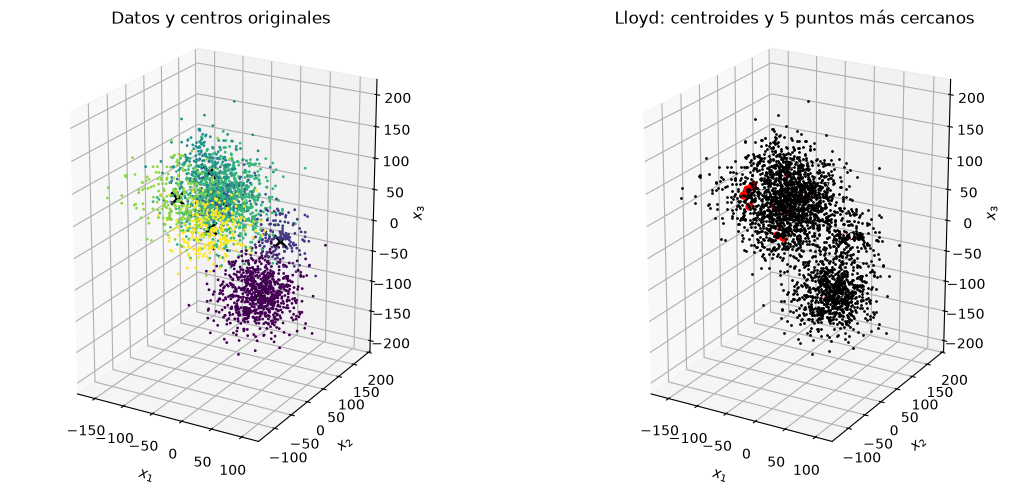

In [ ]:
import matplotlib.pyplot as plt

def plot_centroids_3d(ax, centroids):
    # Adaptación a tres coordenadas de plot_centroids del cuadernillo.
    ax.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2],
               marker='o', s=80, color='w', depthshade=False)
    ax.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2],
               marker='x', s=80, linewidths=2, color='k', depthshade=False)

fig = plt.figure(figsize=(12, 5))
ax_original = fig.add_subplot(121, projection='3d')
ax_lloyd = fig.add_subplot(122, projection='3d')

ax_original.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2],
                    c=y_3d, s=1, depthshade=False)
plot_centroids_3d(ax_original, blob_centers_3d)

ax_lloyd.scatter(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2],
                 c='k', s=1, depthshade=False)
plot_centroids_3d(ax_lloyd, kmeans_3d.cluster_centers_)

for i, centro in enumerate(kmeans_3d.cluster_centers_):
    asignados = X_3d[kmeans_3d.labels_ == i]
    distancias = np.linalg.norm(asignados - centro, axis=1)
    cercanos = asignados[np.argsort(distancias)[:5]]
    ax_lloyd.scatter(cercanos[:, 0], cercanos[:, 1], cercanos[:, 2],
                     c='r', s=25, depthshade=False)
    ax_lloyd.text(*centro, f" C{i+1}", fontsize=8)

minimos = X_3d.min(axis=0)
maximos = X_3d.max(axis=0)
margen = (maximos - minimos) * 0.06
extension = maximos - minimos + 2 * margen

for ax, titulo in [(ax_original, 'Datos y centros originales'),
                   (ax_lloyd, 'Lloyd: centroides y 5 puntos más cercanos')]:
    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_zlabel("$x_3$")
    ax.set_xlim(minimos[0] - margen[0], maximos[0] + margen[0])
    ax.set_ylim(minimos[1] - margen[1], maximos[1] + margen[1])
    ax.set_zlim(minimos[2] - margen[2], maximos[2] + margen[2])
    ax.set_box_aspect(extension)
    ax.view_init(elev=22, azim=-60)

plt.tight_layout()
plt.show()

### 5.5 Resumen de los centroides finales

Para cada grupo mostramos su centroide aprendido, los puntos que Lloyd le asignó y la distancia a sus cinco vecinos más cercanos.

In [ ]:
for i, centro in enumerate(kmeans_3d.cluster_centers_):
    puntos = X_3d[kmeans_3d.labels_ == i]
    distancias = np.linalg.norm(puntos - centro, axis=1)
    cinco_distancias = np.sort(distancias)[:5]

    xyz = ", ".join(f"{valor:.2f}" for valor in centro)
    vecinos = ", ".join(f"{d:.2f}" for d in cinco_distancias)

    print(f"C{i+1:02d} | ({xyz}) | {len(puntos)} puntos | Vecinos: {vecinos}")

C01 | (-89.35, 75.68, 25.62) | 437 puntos | Vecinos: 5.34, 6.40, 7.91, 7.94, 7.95
C02 | (21.49, 39.94, -87.69) | 730 puntos | Vecinos: 2.60, 3.65, 6.57, 9.03, 9.36
C03 | (-58.33, -63.15, 92.36) | 202 puntos | Vecinos: 10.84, 14.67, 16.04, 17.71, 17.85
C04 | (-60.20, 39.09, 102.46) | 315 puntos | Vecinos: 6.20, 6.75, 7.65, 7.70, 9.29
C05 | (-32.87, -6.56, 25.44) | 336 puntos | Vecinos: 6.82, 8.90, 10.79, 13.06, 14.40
C06 | (15.65, 84.43, -12.44) | 297 puntos | Vecinos: 3.74, 3.87, 5.73, 9.38, 9.42
C07 | (-48.57, 100.43, 49.80) | 382 puntos | Vecinos: 6.20, 7.13, 7.59, 7.78, 9.98


---
# 6. Punto 3. DATASETS Anime Face Dataset



Fuente: https://www.kaggle.com/datasets/splcher/animefacedataset




## 6.1. Cargar las imágenes desde Google Drive



Para el modelo se redimensionan las imágenes a 28 × 28 RGB y se aplanan como filas, conservando los píxeles de 0 a 255. La reducción pierde detalle. Las imágenes originales no se modifican.

In [1]:
from google.colab import drive
from pathlib import Path
import zipfile
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

drive.mount('/content/drive')

ruta_zip = Path('/content/drive/MyDrive/SIS420/LAB7/anime_faces/animefacedataset.zip')
if not ruta_zip.is_file():
    ruta_zip = Path('/content/drive/MyDrive/LAB7/anime_faces/archive.zip')
carpeta_imagenes = Path('/content/anime_faces')

with zipfile.ZipFile(ruta_zip) as archivo:
    archivo.extractall(carpeta_imagenes)

archivos_imagenes = sorted(carpeta_imagenes.rglob('*.jpg'))
imagenes = []
for ruta in archivos_imagenes:
    with Image.open(ruta) as imagen:
        imagen = imagen.convert('RGB').resize((28, 28), Image.Resampling.LANCZOS)
        imagenes.append(np.array(imagen).reshape(-1))

X_anime = np.array(imagenes)
del imagenes
print(X_anime.shape)

Mounted at /content/drive
(63565, 2352)


In [2]:
from sklearn.model_selection import train_test_split

# Solo imágenes: todavía no hay etiquetas de clase.
X_train, X_test = train_test_split(X_anime, random_state=42)
print(X_train.shape)
print(X_test.shape)

(47673, 2352)
(15892, 2352)


## 6.2. Encontrar 50 imágenes representativas con K-Means

Se usa `fit_transform()` y se selecciona la imagen de menor distancia a cada centroide con `argmin(axis=0)`. Los 50 grupos no son las categorías de cabello.

In [3]:
from sklearn.cluster import KMeans

k = 50
kmeans = KMeans(n_clusters=k, random_state=42)
X_images_dist = kmeans.fit_transform(X_train)

In [4]:
print(X_images_dist.shape)
print(X_images_dist)

(47673, 50)
[[2378.3421975  3277.11920972 2735.19234953 ... 2801.03748534
  2854.09743497 4303.15121658]
 [3885.05129489 2681.74245263 3090.52003812 ... 2560.77728036
  2931.01568813 2539.70188661]
 [4326.93747642 3074.19581852 4131.76403094 ... 3578.38378366
  3734.07905528 2926.75082649]
 ...
 [2339.51080403 3739.13331471 3023.38982599 ... 3089.2648078
  3046.20829513 4848.81070008]
 [5013.17655707 3535.09206819 3963.7267334  ... 3682.26862414
  4084.03323477 3187.37605229]
 [3925.91130419 3475.74015836 3356.60767392 ... 2765.35156865
  3105.42298765 3773.04045934]]


In [5]:
idxs = np.argmin(X_images_dist, axis=0)
X_representative_images = X_train[idxs]

In [6]:
print(X_representative_images.shape)
print(X_representative_images)

(50, 2352)
[[245 228 150 ... 174 137 114]
 [253 253 253 ... 255 255 255]
 [152 128 134 ... 145  57 105]
 ...
 [255 255 255 ... 138 106 111]
 [255 254 255 ... 198 179 182]
 [252 252 253 ... 255 255 255]]


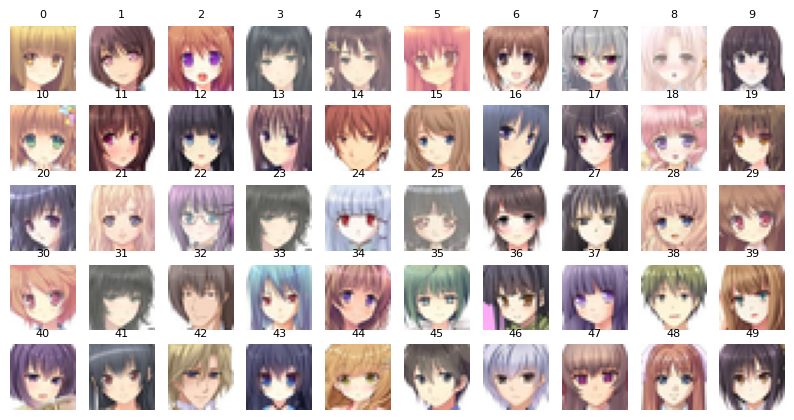

In [7]:
plt.figure(figsize=(10, 5))
for index, X_representative_image in enumerate(X_representative_images):
    plt.subplot(5, 10, index + 1)
    plt.imshow(X_representative_image.reshape(28, 28, 3))
    plt.title(str(index), fontsize=8)
    plt.axis('off')
plt.show()

## 6.3. Etiquetar los representantes

Observa las imágenes numeradas de 0 a 49. Escribe los 50 códigos en ese orden dentro de `y_representative_images`.

| Código | Color predominante del cabello |
|---|---|
| 0 | Negro |
| 1 | Marrón |
| 2 | Rubio / amarillo |
| 3 | Rojo / naranja |
| 4 | Rosa |
| 5 | Violeta |
| 6 | Azul |
| 7 | Verde |
| 8 | Blanco / gris |
| 9 | Otro, varios colores sin predominio o cabello no visible |

Usa la zona del cabello, no el fondo, los ojos ni los accesorios. Si la imagen reducida es ambigua, consulta el original con el índice indicado abajo. La misma regla debe usarse en los tres pasos de etiquetado.

Es necesario tener al menos dos categorías representadas para entrenar el clasificador. Las validaciones solo comprueban que se hayan escrito las respuestas; no asignan clases automáticamente.

In [9]:
y_representative_images = np.array([
    2, 1, 3, 0, 1, 4, 1, 8, 8, 0,  # 0 a 9
    1, 1, 0, 1, 3, 1, 6, 0, 4, 1,  # 10 a 19
    6, 2, 5, 0, 6, 8, 1, 0, 2, 1,  # 20 a 29
    3, 0, 1, 6, 1, 7, 0, 5, 7, 1,  # 30 a 39
    5, 0, 2, 6, 2, 0, 6, 1, 3, 0,  # 40 a 49
], dtype=int)

if len(y_representative_images) != 50:
    raise ValueError('Completa las 50 etiquetas de las imágenes representativas.')
if np.any((y_representative_images < 0) | (y_representative_images > 9)):
    raise ValueError('Los códigos deben estar entre 0 y 9.')
if len(np.unique(y_representative_images)) < 2:
    raise ValueError('Para clasificar se necesitan al menos dos categorías.')

### Consulta de una imagen original (opcional)

Elige su número de representante si necesitas verla con mayor detalle. Esta celda solo muestra la imagen; no modifica los datos del modelo.

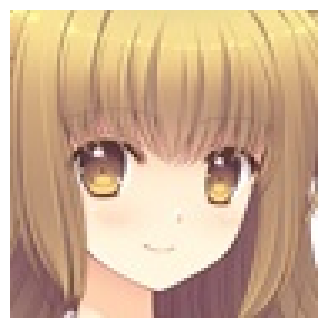

46544_2014.jpg


In [10]:
numero_representante = 0
indices_train, indices_test = train_test_split(
    np.arange(len(archivos_imagenes)), random_state=42)
ruta_original = archivos_imagenes[indices_train[idxs[numero_representante]]]
with Image.open(ruta_original) as imagen:
    plt.figure(figsize=(4, 4))
    plt.imshow(imagen)
    plt.axis('off')
    plt.show()
print(ruta_original.name)

## 6.4. Entrenar el clasificador inicial

 Solo se utilizan las 50 etiquetas que acabas de asignar.

In [11]:
from sklearn.linear_model import LogisticRegression

log_reg2 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
log_reg2.fit(X_representative_images, y_representative_images)

LogisticRegression(max_iter=5000, random_state=42)

## 6.5. Etiquetar una muestra de prueba para evaluar



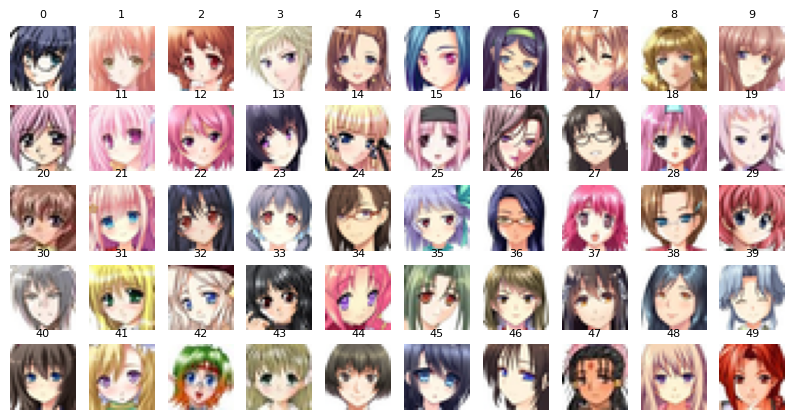

In [12]:
X_test_evaluacion = X_test[:50]

plt.figure(figsize=(10, 5))
for index, imagen in enumerate(X_test_evaluacion):
    plt.subplot(5, 10, index + 1)
    plt.imshow(imagen.reshape(28, 28, 3))
    plt.title(str(index), fontsize=8)
    plt.axis('off')
plt.show()

In [15]:
y_test = np.array([
    6, 3, 3, 2, 1, 6, 5, 1, 2, 1,  # 0 a 9
    4, 4, 4, 0, 2, 4, 5, 0, 4, 4,  # 10 a 19
    1, 4, 0, 8, 1, 5, 6, 4, 1, 3,  # 20 a 29
    8, 2, 8, 0, 4, 7, 1, 1, 6, 6,  # 30 a 39
    0, 2, 3, 2, 0, 6, 1, 0, 2, 3,  # 40 a 49
], dtype=int)

if len(y_test) != 50:
    raise ValueError('Completa las 50 etiquetas del conjunto de prueba.')
if np.any((y_test < 0) | (y_test > 9)):
    raise ValueError('Los códigos deben estar entre 0 y 9.')

In [16]:
log_reg2.score(X_test_evaluacion, y_test)

0.42

## 6.6. Aprendizaje semisupervisado: propagar etiquetas

Cada imagen de entrenamiento recibe la categoría de la imagen representativa de su cluster. Se propaga a todo el entrenamiento y luego se entrena con las primeras 1.000 imágenes. Las etiquetas propagadas son provisionales y pueden contener errores.

In [17]:
y_train_propagated = np.empty(len(X_train))
for i in range(k):
  y_train_propagated[kmeans.labels_==i] = y_representative_images[i]

In [18]:
log_reg3 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
log_reg3.fit(X_train[:1000], y_train_propagated[:1000])
log_reg3.score(X_test_evaluacion, y_test)

0.34

## 6.7. Aprendizaje activo

Se calculan probabilidades sobre las primeras 1.000 imágenes utilizadas por el clasificador, igual que en el ejemplo del ingeniero. Se ordena la probabilidad máxima de cada imagen y se seleccionan las 50 de menor confianza.

In [19]:
probas = log_reg3.predict_proba(X_train[:1000])
labels_ixs = np.argmax(probas, axis=1)
labels = np.array([proba[ix] for proba, ix in zip(probas, labels_ixs)])
sorted_ixs = np.argsort(labels)
labels[sorted_ixs[:10]]

array([0.9998297 , 0.9998391 , 0.9998532 , 0.99985494, 0.9998726 ,
       0.99987638, 0.99987826, 0.99988518, 0.9998901 , 0.99989969])

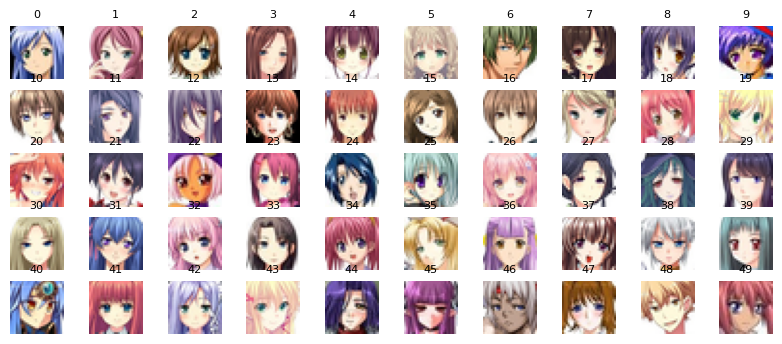

In [20]:
X_lowest = X_train[:1000][sorted_ixs[:k]]
plt.figure(figsize=(10, 4))
for index, img in enumerate(X_lowest):
    plt.subplot(k // 10, 10, index + 1)
    plt.imshow(img.reshape(28, 28, 3))
    plt.title(str(index), fontsize=8)
    plt.axis('off')
plt.show()

### Consultar las etiquetas de las imágenes seleccionadas



In [22]:
y_lowest = np.array([
    6, 4, 1, 1, 5, 2, 7, 1, 5, 6,  # 0 a 9
    1, 6, 5, 3, 3, 1, 1, 2, 4, 2,  # 10 a 19
    3, 0, 4, 4, 6, 7, 4, 0, 7, 1,  # 20 a 29
    2, 6, 4, 1, 4, 2, 5, 1, 8, 7,  # 30 a 39
    6, 3, 5, 2, 5, 5, 8, 1, 2, 3,  # 40 a 49
], dtype=int)

if len(y_lowest) != 50:
    raise ValueError('Completa las 50 etiquetas seleccionadas por aprendizaje activo.')
if np.any((y_lowest < 0) | (y_lowest > 9)):
    raise ValueError('Los códigos deben estar entre 0 y 9.')
y_lowest

array([6, 4, 1, 1, 5, 2, 7, 1, 5, 6, 1, 6, 5, 3, 3, 1, 1, 2, 4, 2, 3, 0,
       4, 4, 6, 7, 4, 0, 7, 1, 2, 6, 4, 1, 4, 2, 5, 1, 8, 7, 6, 3, 5, 2,
       5, 5, 8, 1, 2, 3])

In [23]:
y_train2 = y_train_propagated[:1000].copy()
y_train2[sorted_ixs[:k]] = y_lowest

In [24]:
log_reg5 = LogisticRegression(solver="lbfgs", max_iter=5000, random_state=42)
log_reg5.fit(X_train[:1000], y_train2)
log_reg5.score(X_test_evaluacion, y_test)

0.34